In [1]:
from google.colab import files
import pandas as pd

uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())

display(df.head())

Saving complaints_processed.csv to complaints_processed.csv
Dataset shape: (162421, 3)
Column names: ['Unnamed: 0', 'product', 'narrative']


,Unnamed: 0,product,narrative
0,0,credit_card,purchase order day shipping amount receive pro...
1,1,credit_card,forwarded message date tue subject please inve...
2,2,retail_banking,forwarded message cc sent friday pdt subject f...
3,3,credit_reporting,payment history missing credit report speciali...
4,4,credit_reporting,payment history missing credit report made mis...


In [2]:
print(df.columns.tolist())

['Unnamed: 0', 'product', 'narrative']


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
from google.colab import files

uploaded = files.upload()

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())

display(df.head())

Saving complaints_processed.csv to complaints_processed (1).csv
Dataset shape: (162421, 3)
Column names: ['Unnamed: 0', 'product', 'narrative']


,Unnamed: 0,product,narrative
0,0,credit_card,purchase order day shipping amount receive pro...
1,1,credit_card,forwarded message date tue subject please inve...
2,2,retail_banking,forwarded message cc sent friday pdt subject f...
3,3,credit_reporting,payment history missing credit report speciali...
4,4,credit_reporting,payment history missing credit report made mis...


In [5]:
# Find the complaint text column
text_candidates = [
    "Consumer complaint narrative",
    "consumer_complaint_narrative",
    "narrative",
    "complaint_text",
    "text"
]

# Find the target category column
label_candidates = [
    "Product",
    "product",
    "category",
    "complaint_category",
    "label"
]

text_col = next(
    (c for c in text_candidates if c in df.columns),
    None
)

label_col = next(
    (c for c in label_candidates if c in df.columns),
    None
)

if text_col is None or label_col is None:
    raise ValueError(
        "Text or category column not found. "
        "Check the column names printed in Step 2."
    )

df = df[[text_col, label_col]].copy()
df.columns = ["Complaint", "Category"]

# Remove missing values and empty complaint text
df = df.dropna(subset=["Complaint", "Category"])
df["Complaint"] = df["Complaint"].astype(str).str.strip()
df["Category"] = df["Category"].astype(str).str.strip()
df = df[df["Complaint"] != ""]
df = df[df["Category"] != ""]

print("Cleaned dataset shape:", df.shape)
print("\nCategory distribution:")
print(df["Category"].value_counts())

Cleaned dataset shape: (162411, 2)

Category distribution:
Category
credit_reporting       91172
debt_collection        23148
mortgages_and_loans    18990
credit_card            15566
retail_banking         13535
Name: count, dtype: int64


In [6]:
counts = df["Category"].value_counts()
valid_categories = counts[counts >= 2].index

df = df[df["Category"].isin(valid_categories)].copy()

# Sample if the dataset is large
if len(df) > 30000:
    df = (
        df.groupby("Category", group_keys=False)
          .apply(
              lambda group: group.sample(
                  n=max(
                      1,
                      round(30000 * len(group) / len(df))
                  ),
                  random_state=42
              )
          )
          .copy()
    )

X = df["Complaint"]
y = df["Category"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 24000
Testing records: 6000


/tmp/ipykernel_1135/1879874422.py:10: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


In [7]:
tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    max_features=10000,
    ngram_range=(1, 2),
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training feature shape:", X_train_tfidf.shape)
print("Testing feature shape:", X_test_tfidf.shape)

Training feature shape: (24000, 10000)
Testing feature shape: (6000, 10000)


In [8]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, classification_report
)
import time

dt_model = DecisionTreeClassifier(
    max_depth=100,
    class_weight="balanced",
    random_state=42
)

start = time.perf_counter()
dt_model.fit(X_train_tfidf, y_train)
dt_training_time = time.perf_counter() - start

dt_pred = dt_model.predict(X_test_tfidf)

print("DECISION TREE RESULTS")
print("Accuracy:", accuracy_score(y_test, dt_pred))
print("Precision:", precision_score(
    y_test, dt_pred, average="macro", zero_division=0
))
print("Recall:", recall_score(
    y_test, dt_pred, average="macro", zero_division=0
))
print("F1-Score:", f1_score(
    y_test, dt_pred, average="macro", zero_division=0
))
print("Training Time:", dt_training_time, "seconds")
print("\nClassification Report:\n")
print(classification_report(
    y_test, dt_pred, zero_division=0
))

DECISION TREE RESULTS
Accuracy: 0.7625
Precision: 0.6838686590337304
Recall: 0.6843940296915908
F1-Score: 0.6839082352378629
Training Time: 33.64592189199993 seconds

Classification Report:

                     precision    recall  f1-score   support

        credit_card       0.57      0.56      0.56       575
   credit_reporting       0.86      0.86      0.86      3368
    debt_collection       0.63      0.63      0.63       855
mortgages_and_loans       0.69      0.66      0.68       702
     retail_banking       0.67      0.71      0.69       500

           accuracy                           0.76      6000
          macro avg       0.68      0.68      0.68      6000
       weighted avg       0.76      0.76      0.76      6000



In [9]:
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(
    n_neighbors=5,
    metric="cosine",
    algorithm="brute"
)

start = time.perf_counter()
knn_model.fit(X_train_tfidf, y_train)
knn_training_time = time.perf_counter() - start

knn_pred = knn_model.predict(X_test_tfidf)

print("KNN RESULTS")
print("Accuracy:", accuracy_score(y_test, knn_pred))
print("Precision:", precision_score(
    y_test, knn_pred, average="macro", zero_division=0
))
print("Recall:", recall_score(
    y_test, knn_pred, average="macro", zero_division=0
))
print("F1-Score:", f1_score(
    y_test, knn_pred, average="macro", zero_division=0
))
print("Training Time:", knn_training_time, "seconds")
print("\nClassification Report:\n")
print(classification_report(
    y_test, knn_pred, zero_division=0
))

KNN RESULTS
Accuracy: 0.8196666666666667
Precision: 0.7929710686614355
Recall: 0.7431843461511594
F1-Score: 0.764917029350719
Training Time: 0.10930480299998635 seconds

Classification Report:

                     precision    recall  f1-score   support

        credit_card       0.68      0.70      0.69       575
   credit_reporting       0.85      0.92      0.88      3368
    debt_collection       0.76      0.64      0.70       855
mortgages_and_loans       0.84      0.69      0.75       702
     retail_banking       0.84      0.77      0.80       500

           accuracy                           0.82      6000
          macro avg       0.79      0.74      0.76      6000
       weighted avg       0.82      0.82      0.82      6000



In [10]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC(
    class_weight="balanced",
    max_iter=5000,
    random_state=42
)

start = time.perf_counter()
svm_model.fit(X_train_tfidf, y_train)
svm_training_time = time.perf_counter() - start

svm_pred = svm_model.predict(X_test_tfidf)

print("SVM RESULTS")
print("Accuracy:", accuracy_score(y_test, svm_pred))
print("Precision:", precision_score(
    y_test, svm_pred, average="macro", zero_division=0
))
print("Recall:", recall_score(
    y_test, svm_pred, average="macro", zero_division=0
))
print("F1-Score:", f1_score(
    y_test, svm_pred, average="macro", zero_division=0
))
print("Training Time:", svm_training_time, "seconds")
print("\nClassification Report:\n")
print(classification_report(
    y_test, svm_pred, zero_division=0
))

SVM RESULTS
Accuracy: 0.8565
Precision: 0.8091178270270444
Recall: 0.8257981800493548
F1-Score: 0.817195751227014
Training Time: 9.14393546600013 seconds

Classification Report:

                     precision    recall  f1-score   support

        credit_card       0.73      0.78      0.75       575
   credit_reporting       0.92      0.90      0.91      3368
    debt_collection       0.75      0.78      0.76       855
mortgages_and_loans       0.80      0.81      0.80       702
     retail_banking       0.84      0.86      0.85       500

           accuracy                           0.86      6000
          macro avg       0.81      0.83      0.82      6000
       weighted avg       0.86      0.86      0.86      6000



In [11]:
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB()

start = time.perf_counter()
nb_model.fit(X_train_tfidf, y_train)
nb_training_time = time.perf_counter() - start

nb_pred = nb_model.predict(X_test_tfidf)

print("NAIVE BAYES RESULTS")
print("Accuracy:", accuracy_score(y_test, nb_pred))
print("Precision:", precision_score(
    y_test, nb_pred, average="macro", zero_division=0
))
print("Recall:", recall_score(
    y_test, nb_pred, average="macro", zero_division=0
))
print("F1-Score:", f1_score(
    y_test, nb_pred, average="macro", zero_division=0
))
print("Training Time:", nb_training_time, "seconds")
print("\nClassification Report:\n")
print(classification_report(
    y_test, nb_pred, zero_division=0
))

NAIVE BAYES RESULTS
Accuracy: 0.8323333333333334
Precision: 0.7891470267405527
Recall: 0.798062824048968
F1-Score: 0.7907064678893474
Training Time: 0.24137100899997677 seconds

Classification Report:

                     precision    recall  f1-score   support

        credit_card       0.72      0.75      0.73       575
   credit_reporting       0.89      0.89      0.89      3368
    debt_collection       0.77      0.63      0.70       855
mortgages_and_loans       0.72      0.88      0.79       702
     retail_banking       0.84      0.85      0.84       500

           accuracy                           0.83      6000
          macro avg       0.79      0.80      0.79      6000
       weighted avg       0.83      0.83      0.83      6000



In [12]:
import pandas as pd

results_df = pd.DataFrame([
    {
        "Model": "Decision Tree",
        "Accuracy": accuracy_score(y_test, dt_pred),
        "Precision": precision_score(
            y_test, dt_pred, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_test, dt_pred, average="macro", zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, dt_pred, average="macro", zero_division=0
        ),
        "Training Time (seconds)": dt_training_time
    },
    {
        "Model": "KNN",
        "Accuracy": accuracy_score(y_test, knn_pred),
        "Precision": precision_score(
            y_test, knn_pred, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_test, knn_pred, average="macro", zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, knn_pred, average="macro", zero_division=0
        ),
        "Training Time (seconds)": knn_training_time
    },
    {
        "Model": "SVM",
        "Accuracy": accuracy_score(y_test, svm_pred),
        "Precision": precision_score(
            y_test, svm_pred, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_test, svm_pred, average="macro", zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, svm_pred, average="macro", zero_division=0
        ),
        "Training Time (seconds)": svm_training_time
    },
    {
        "Model": "Naive Bayes",
        "Accuracy": accuracy_score(y_test, nb_pred),
        "Precision": precision_score(
            y_test, nb_pred, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_test, nb_pred, average="macro", zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, nb_pred, average="macro", zero_division=0
        ),
        "Training Time (seconds)": nb_training_time
    }
])

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,Training Time (seconds)
0,Decision Tree,0.7625,0.6839,0.6844,0.6839,33.6459
1,KNN,0.8197,0.7930,0.7432,0.7649,0.1093
2,SVM,0.8565,0.8091,0.8258,0.8172,9.1439
3,Naive Bayes,0.8323,0.7891,0.7981,0.7907,0.2414


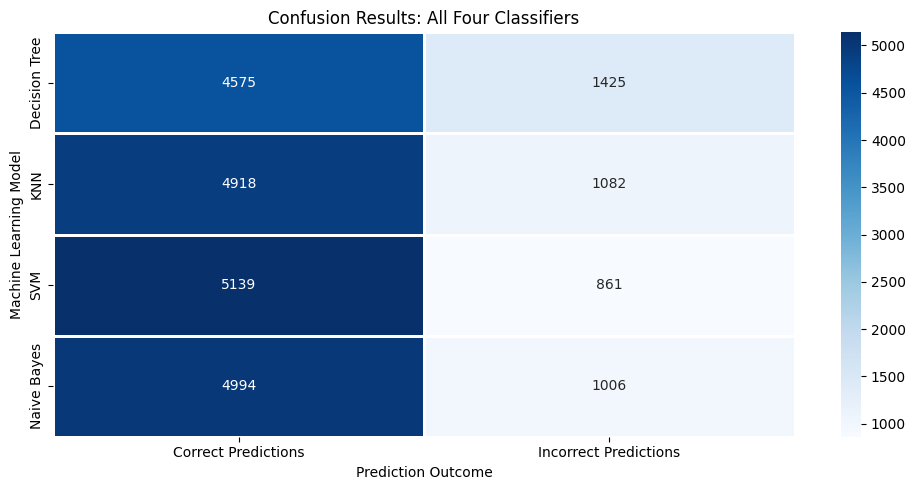

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Predictions from all four classifiers
predictions = {
    "Decision Tree": dt_pred,
    "KNN": knn_pred,
    "SVM": svm_pred,
    "Naive Bayes": nb_pred
}

labels = sorted(y_test.unique())

# Calculate correct and incorrect predictions for each model
comparison = []

for model_name, pred in predictions.items():
    cm = confusion_matrix(y_test, pred, labels=labels)

    comparison.append({
        "Model": model_name,
        "Correct Predictions": np.trace(cm),
        "Incorrect Predictions": cm.sum() - np.trace(cm)
    })

comparison_df = pd.DataFrame(comparison).set_index("Model")

# ONE common graph
plt.figure(figsize=(10, 5))

sns.heatmap(
    comparison_df,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=1,
    cbar=True
)

plt.title("Confusion Results: All Four Classifiers")
plt.xlabel("Prediction Outcome")
plt.ylabel("Machine Learning Model")
plt.tight_layout()
plt.savefig("common_confusion_graph.png", dpi=300)
plt.show()

In [18]:
from google.colab import files
files.download("common_confusion_graph.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
results_df.to_excel(
    "customer_complaint_model_comparison.xlsx",
    index=False
)

files.download("customer_complaint_model_comparison.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>